# Самостоятельная работа: модулярность и анализ scRNA-seq

In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import leidenalg

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Variable names are not unique")  
warnings.filterwarnings("ignore", message="IProgress not found")
sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white", frameon=False)
print("scanpy", sc.__version__)

scanpy 1.11.5


---
# Задание 1. Модулярность вручную

![Граф из 9 вершин](data/graph_pic.jpg)

Сообщества: **A = {1, 2, 3}**, **B = {4, 5, 6}**, **C = {7, 8, 9}**.

### 1. Число рёбер `m`

По рисунку:

| Тип | Рёбра | Число |
|---|---|---|
| внутри A | 1–2, 1–3, 2–3 | 3 |
| внутри B | 4–5, 4–6, 5–6 | 3 |
| внутри C | 7–8, 7–9, 8–9 | 3 |
| между сообществами (пунктир) | 3–4, 6–7, 1–9 | 3 |

$$m = 3 + 3 + 3 + 3 = \mathbf{12}.$$

### 2. `l_c` и `d_c`

Степени вершин (внутренние + внешние рёбра):

| Вершина | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| Степень $k_i$ | 3 | 2 | 3 | 3 | 2 | 3 | 3 | 2 | 3 |

Проверка: $\sum_i k_i = 24 = 2m$ ✓.

| Сообщество | $l_c$ | $d_c$ |
|---|---|---|
| A = {1,2,3} | 3 | 3 + 2 + 3 = 8 |
| B = {4,5,6} | 3 | 3 + 2 + 3 = 8 |
| C = {7,8,9} | 3 | 3 + 2 + 3 = 8 |

### 3. Расчёт модулярности

Для каждого сообщества:

$$\frac{l_c}{m} - \left(\frac{d_c}{2m}\right)^2 = \frac{3}{12} - \left(\frac{8}{24}\right)^2 = 0.25 - \frac{1}{9} = \frac{9 - 4}{36} = \frac{5}{36} \approx 0.1389.$$

Сообщества симметричны, поэтому

$$Q = 3 \cdot \frac{5}{36} = \frac{5}{12} \approx \mathbf{0.417}.$$

Проверим расчёт кодом: по формуле из задания и через `networkx` (общая формула $Q=\frac{1}{2m}\sum_{ij}(A_{ij}-\frac{k_ik_j}{2m})\mathbf 1(c_i=c_j)$ при $\gamma=1$).

In [2]:
import networkx as nx

edges = [(1, 2), (1, 3), (2, 3),      # A
         (4, 5), (4, 6), (5, 6),      # B
         (7, 8), (7, 9), (8, 9),      # C
         (3, 4), (6, 7), (1, 9)]      # между сообществами
communities = {"A": {1, 2, 3}, "B": {4, 5, 6}, "C": {7, 8, 9}}

G_toy = nx.Graph(edges)
m = G_toy.number_of_edges()
deg = dict(G_toy.degree())

rows = []
for name, nodes in communities.items():
    l_c = G_toy.subgraph(nodes).number_of_edges()
    d_c = sum(deg[v] for v in nodes)
    rows.append({"сообщество": name, "l_c": l_c, "d_c": d_c,
                 "l_c/m": l_c / m, "(d_c/2m)^2": (d_c / (2 * m)) ** 2,
                 "вклад": l_c / m - (d_c / (2 * m)) ** 2})
table = pd.DataFrame(rows).set_index("сообщество")
display(table.round(4))

Q_manual = table["вклад"].sum()
Q_nx = nx.community.modularity(G_toy, communities.values())
print(f"m = {m}")
print(f"Q (по формуле задания) = {Q_manual:.4f}  (= 5/12 = {5/12:.4f})")
print(f"Q (networkx)           = {Q_nx:.4f}")

,l_c,d_c,l_c/m,(d_c/2m)^2,вклад
сообщество,,,,,
A,3,8,0.25,0.1111,0.1389
B,3,8,0.25,0.1111,0.1389
C,3,8,0.25,0.1111,0.1389


m = 12
Q (по формуле задания) = 0.4167  (= 5/12 = 0.4167)
Q (networkx)           = 0.4167


### 4. Смысл второго члена

- $\frac{l_c}{m}$ — **наблюдаемая** доля рёбер, лежащих внутри сообщества $c$.
- $\left(\frac{d_c}{2m}\right)^2$ — **ожидаемая** доля таких рёбер, если бы рёбра соединяли вершины случайно с сохранением их степеней (нулевая модель конфигурационного типа). Каждое ребро имеет два «конца»; доля концов, принадлежащих сообществу $c$, равна $d_c/2m$, и вероятность того, что оба конца случайного ребра попадут в $c$, ≈ $(d_c/2m)^2$.

Без вычитания доля внутренних рёбер была бы максимальной (= 1) для тривиального разбиения «все вершины в одном сообществе», т.е. метрика поощряла бы укрупнение. Второй член убирает ту часть внутренних связей, которая появилась бы **просто случайно** из-за степеней вершин: например, для одного сообщества из всего графа $Q = 1 - 1^2 = 0$.

**Положительное $Q$** означает, что внутри сообществ рёбер больше, чем ожидается при случайном соединении: разбиение отражает реальную модульную структуру. У нас $Q \approx 0.417$: 75 % рёбер лежат внутри групп при ожидаемых $3 \cdot (1/3)^2 = 33$ %.

**$Q$ — не вероятность.** Это разность двух долей: она может быть отрицательной (разбиение хуже случайного, например каждая пара соседей разнесена по разным группам), всегда $Q < 1$, и её значения не суммируются к единице и не интерпретируются как шанс какого-либо события. Это функция качества разбиения, которую оптимизируют Louvain/Leiden.

---
# Задание 2. Селезёнка мыши (10x Genomics, ~1k клеток)

**Данные:** [Splenocytes from C57BL/6 mice, 1k cells (v2, Cell Ranger 4.0.0)](https://www.10xgenomics.com/datasets/splenocytes-from-c-57-bl-6-mice-1-k-cells-v-2-2-standard-4-0-0), файл *Gene Expression — Feature / cell matrix HDF5 (filtered)*. Это UMI-счётчики для баркодов, которые Cell Ranger уже признал клетками.

Селезёнка — вторичный лимфоидный орган, поэтому заранее ожидаем в основном **B- и T-лимфоциты**, а также NK-клетки, миелоидные клетки (моноциты, макрофаги красной пульпы, дендритные клетки, нейтрофилы) и, возможно, эритроидные клетки.

In [3]:
data_path = Path("data/sc5p_v2_mm_c57bl6_splenocyte_1k_filtered_feature_bc_matrix.h5")
adata = sc.read_10x_h5(data_path)
adata.var_names_make_unique()

print(adata.var["feature_types"].value_counts())
n_cells_raw, n_genes_raw = adata.shape
print(f"До QC: {n_cells_raw} клеток × {n_genes_raw} генов")
adata

feature_types
Gene Expression    32285
Name: count, dtype: int64


До QC: 1119 клеток × 32285 генов


AnnData object with n_obs × n_vars = 1119 × 32285
    var: 'gene_ids', 'feature_types', 'genome'

## 2.1. QC

У мыши митохондриальные гены начинаются с префикса `mt-` (строчными буквами, в отличие от `MT-` у человека).

In [4]:
adata.var["mt"] = adata.var_names.str.startswith("mt-")
print("Митохондриальных генов:", adata.var["mt"].sum())
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

qc_cols = ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
adata.obs[qc_cols].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2)

Митохондриальных генов: 13


,total_counts,n_genes_by_counts,pct_counts_mt
count,1119.00,1119.00,1119.00
mean,4981.96,1823.40,2.97
std,3785.76,708.29,2.91
min,501.00,198.00,0.00
1%,597.18,388.18,0.19
5%,1042.40,696.40,0.95
50%,4133.00,1749.00,2.53
95%,10729.30,3072.40,5.65
99%,18135.16,4068.10,13.94
max,46568.00,5772.00,49.58


Выбранные пороги (обоснование ниже, под графиками):

| Метрика | Порог |
|---|---|
| `n_genes_by_counts` | ≥ 500 и < 4500 |
| `pct_counts_mt` | < 10 % |
| гены | детектированы минимум в 3 клетках |

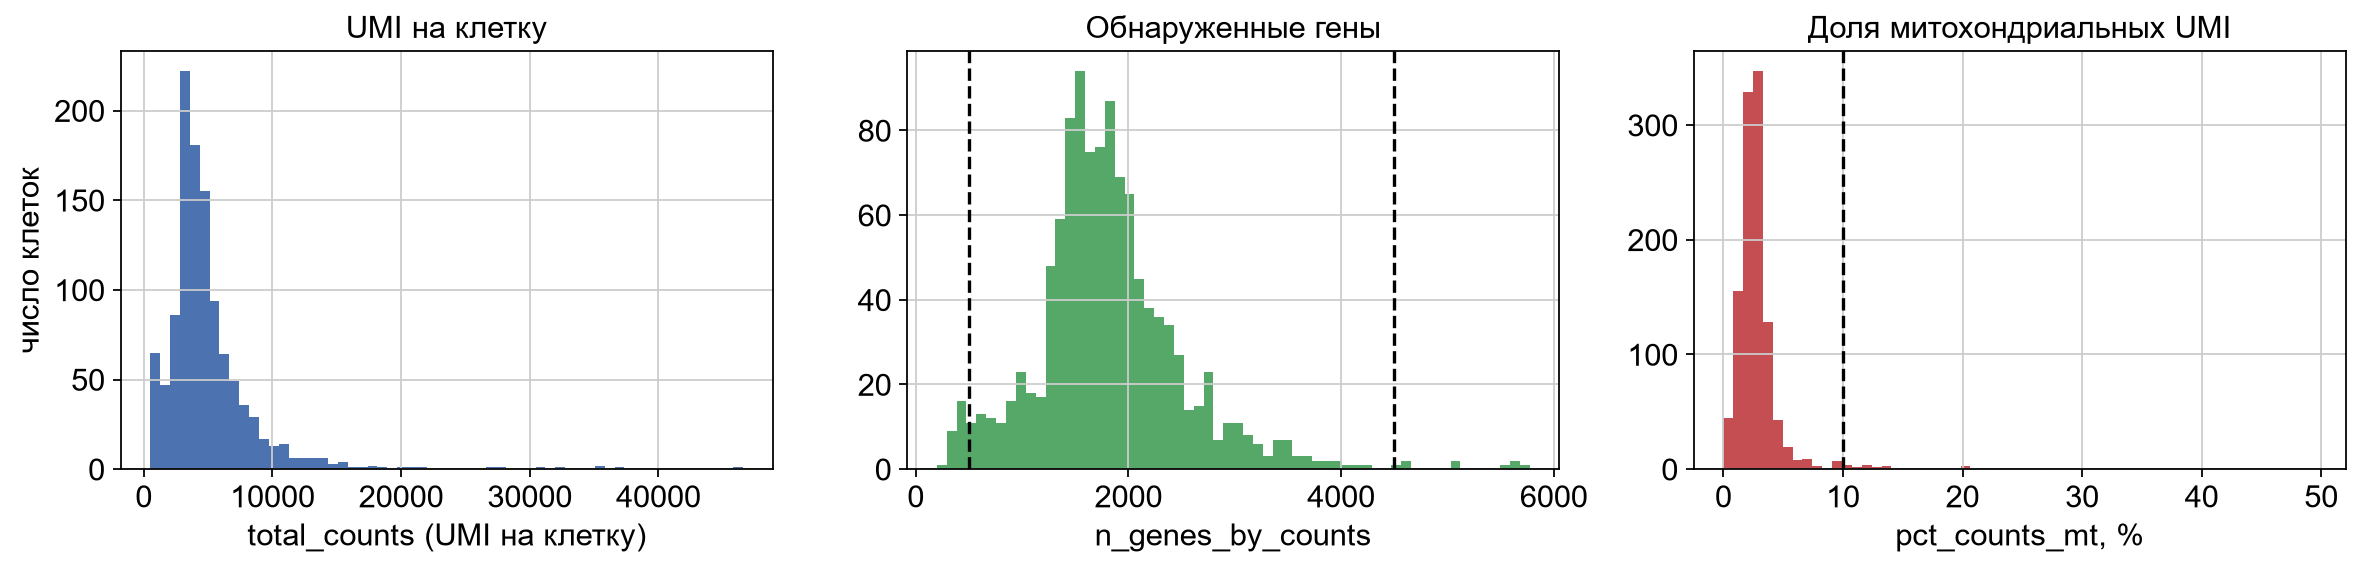

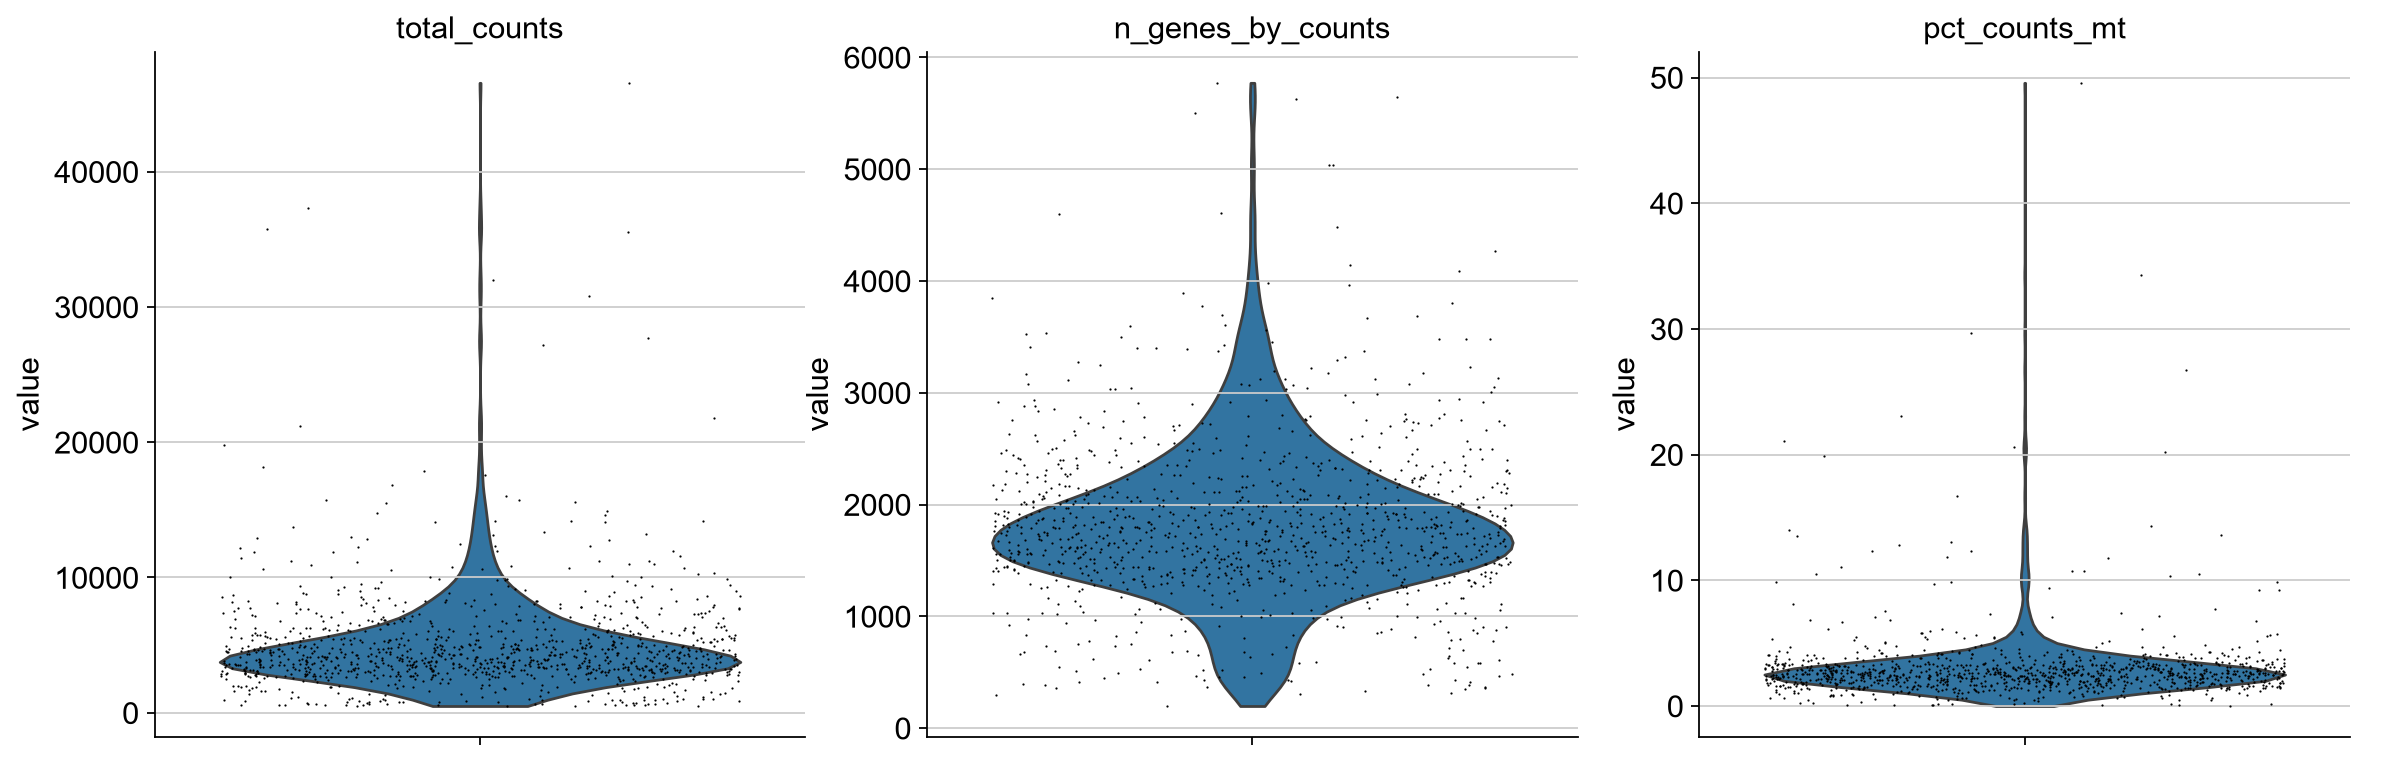

In [5]:
MIN_GENES, MAX_GENES, MAX_MT, MIN_CELLS = 500, 4500, 10, 3

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
obs = adata.obs
axes[0].hist(obs["total_counts"], bins=60, color="#4C72B0")
axes[0].set(xlabel="total_counts (UMI на клетку)", ylabel="число клеток", xscale="linear",
            title="UMI на клетку")
axes[1].hist(obs["n_genes_by_counts"], bins=60, color="#55A868")
axes[1].axvline(MIN_GENES, ls="--", c="k"); axes[1].axvline(MAX_GENES, ls="--", c="k")
axes[1].set(xlabel="n_genes_by_counts", title="Обнаруженные гены")
axes[2].hist(obs["pct_counts_mt"], bins=60, color="#C44E52")
axes[2].axvline(MAX_MT, ls="--", c="k")
axes[2].set(xlabel="pct_counts_mt, %", title="Доля митохондриальных UMI")
plt.tight_layout(); plt.show()

sc.pl.violin(adata, qc_cols, jitter=0.4, multi_panel=True)

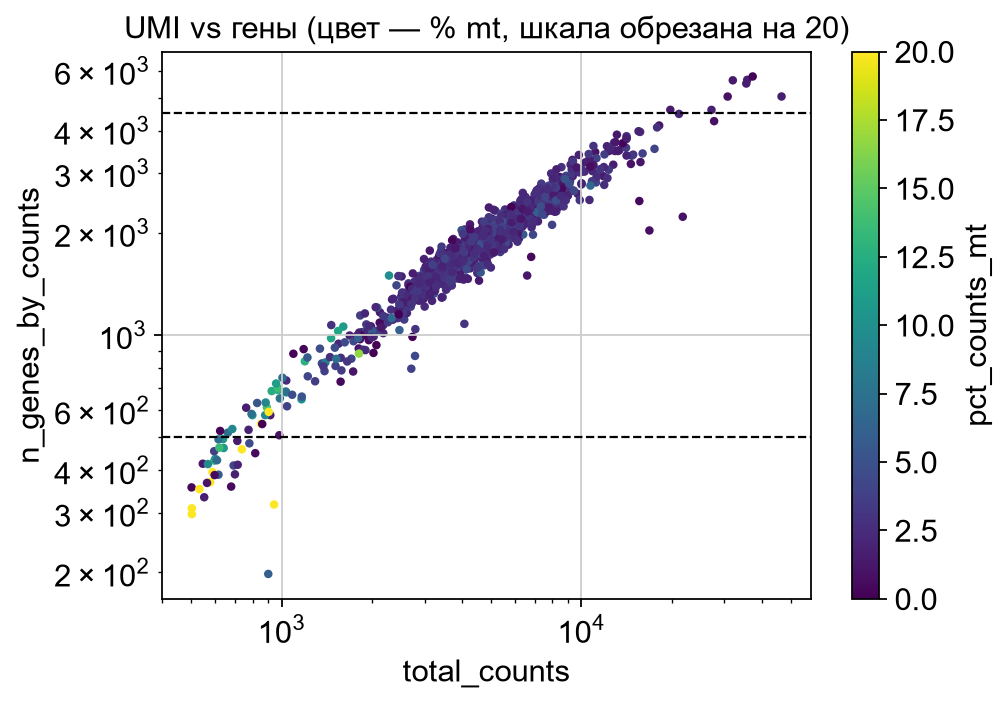

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sca = ax.scatter(obs["total_counts"], obs["n_genes_by_counts"], c=obs["pct_counts_mt"],
                 s=8, cmap="viridis", vmax=20)
ax.axhline(MIN_GENES, ls="--", c="k", lw=1); ax.axhline(MAX_GENES, ls="--", c="k", lw=1)
ax.set(xscale="log", yscale="log", xlabel="total_counts", ylabel="n_genes_by_counts",
       title="UMI vs гены (цвет — % mt, шкала обрезана на 20)")
plt.colorbar(sca, label="pct_counts_mt")
plt.show()

**Почему именно такие пороги**

- **`n_genes_by_counts ≥ 500`.** Медиана ≈ 1750 генов, 5-й перцентиль ≈ 700. Классический порог 200 здесь почти ничего не отсекает (ниже него лишь 1 баркод), а клетки с < 500 генами — левый «хвост» распределения, обычно повреждённые клетки или капли с остаточной (ambient) РНК. Порог 500 убирает ≈ 3 % баркодов и оставляет даже мелкие лимфоциты, у которых транскриптом сам по себе небольшой.
- **`n_genes_by_counts < 4500`.** Правый хвост (99-й перцентиль ≈ 4070, максимум ≈ 5800 генов; выше 4500 — 8 клеток, < 1 %) — кандидаты в дублеты (две клетки в одной капле). При ожидаемой частоте дублетов ~1 % для ~1000 клеток 10x срезаем только явные выбросы, чтобы не потерять крупные активированные клетки и миелоидные клетки с богатым транскриптомом.
- **`pct_counts_mt < 10 %`.** Медиана ≈ 2.5 %, 95-й перцентиль ≈ 5.7 %, а дальше идёт длинный хвост до 50 % — признак повреждённых клеток, потерявших цитоплазматическую мРНК. Порог 5 % (как в PBMC 3k) отрезал бы ~6 % клеток и задел бы метаболически активные клетки на плече распределения; 10 % — стандартный более мягкий порог для тканей мыши, отсекающий именно хвост (≈ 2–3 %).
- **`total_counts`** отдельно не фильтруем: он сильно коррелирует с числом генов (см. scatter), и пороги по генам уже убирают оба хвоста.
- **Гены в ≥ 3 клетках.** Гены, увиденные в 0–2 клетках, не несут информации о структуре популяций, но увеличивают размер матрицы и шум.

In [7]:
mask_low = adata.obs["n_genes_by_counts"] < MIN_GENES
mask_high = adata.obs["n_genes_by_counts"] >= MAX_GENES
mask_mt = adata.obs["pct_counts_mt"] >= MAX_MT
print(f"< {MIN_GENES} генов:      {mask_low.sum()} клеток")
print(f">= {MAX_GENES} генов:    {mask_high.sum()} клеток")
print(f">= {MAX_MT}% mt:         {mask_mt.sum()} клеток")
print(f"удаляется всего:    {(mask_low | mask_high | mask_mt).sum()} клеток (критерии пересекаются)")

sc.pp.filter_cells(adata, min_genes=MIN_GENES)
sc.pp.filter_genes(adata, min_cells=MIN_CELLS)
adata = adata[(adata.obs["n_genes_by_counts"] < MAX_GENES) &
              (adata.obs["pct_counts_mt"] < MAX_MT)].copy()

n_cells_qc, n_genes_qc = adata.shape
print(f"\nДо QC:    {n_cells_raw} клеток × {n_genes_raw} генов")
print(f"После QC: {n_cells_qc} клеток × {n_genes_qc} генов "
      f"(сохранено {n_cells_qc / n_cells_raw:.1%} клеток)")

< 500 генов:      30 клеток
>= 4500 генов:    8 клеток
>= 10% mt:         26 клеток
удаляется всего:    52 клеток (критерии пересекаются)

До QC:    1119 клеток × 32285 генов
После QC: 1067 клеток × 13022 генов (сохранено 95.4% клеток)


## 2.2. Нормализация и HVG

Порядок как на семинаре: сырые счётчики сохраняем в `layers["counts"]`, HVG ищем методом `seurat_v3` (он работает на **сырых** счётчиках и моделирует зависимость дисперсии от среднего), затем нормализуем каждую клетку на 10 000 UMI и логарифмируем `log1p`.

**Зачем HVG.** Большинство из ~13 000 оставшихся генов либо почти не экспрессируются, либо экспрессируются одинаково во всех клетках (housekeeping-гены) — они дают в основном технический шум. Биологические различия между типами клеток сосредоточены в генах с высокой вариабельностью *сверх* ожидаемой для их уровня экспрессии. Отбор HVG снижает шум и размерность перед PCA.

**Почему 2000.** Это стандартное значение (Seurat/Scanpy) — примерно 15 % детектированных генов. Для ~1000 клеток с умеренным разнообразием типов этого достаточно, чтобы захватить маркеры основных популяций иммунных клеток, и не так много, чтобы в PCA доминировал шум. Результаты кластеризации обычно устойчивы в диапазоне 1000–3000 HVG.

Число HVG: 2000


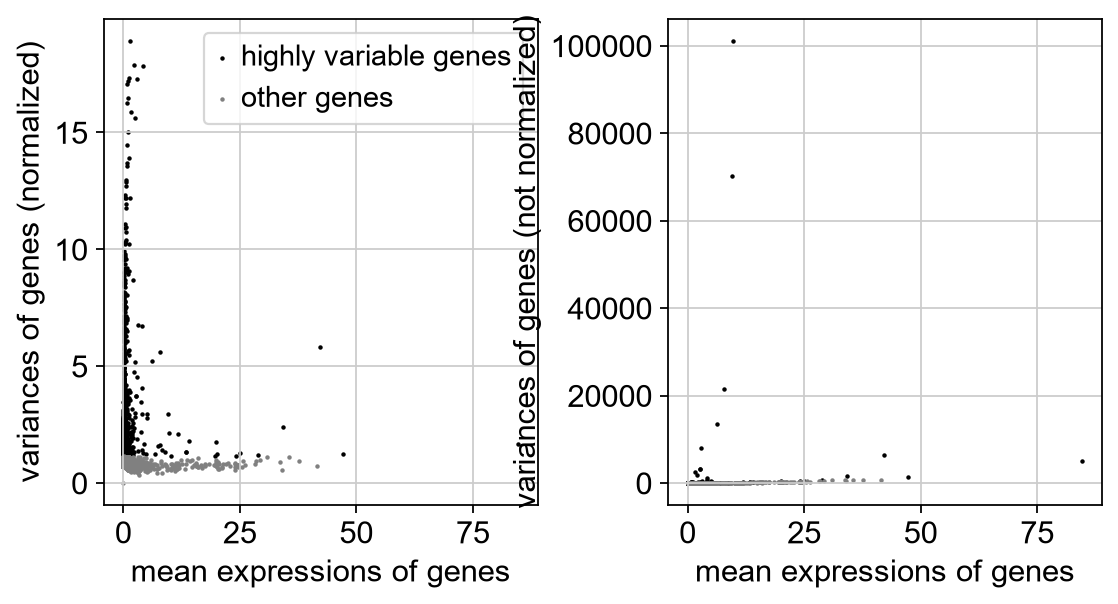

In [8]:
N_HVG = 2000
adata.layers["counts"] = adata.X.copy()
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=N_HVG)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

print("Число HVG:", adata.var["highly_variable"].sum())
sc.pl.highly_variable_genes(adata)

In [9]:
# Попали ли в HVG маркеры, которые будем смотреть дальше
marker_genes = ["Cd79a", "Ms4a1", "Cd3e", "Cd8a", "Cd4", "Nkg7", "Gzma",
                "Lyz2", "S100a8", "C1qa", "Itgax", "H2-Ab1", "Hbb-bs"]
marker_genes = [g for g in marker_genes if g in adata.var_names]
adata.var.loc[marker_genes, ["highly_variable", "highly_variable_rank", "means"]]

,highly_variable,highly_variable_rank,means
Cd79a,False,NaN,14.826617
Ms4a1,False,NaN,3.665417
Cd3e,True,248.0,1.261481
Cd8a,True,142.0,0.298969
Cd4,True,542.0,0.148079
Nkg7,True,70.0,0.798500
Gzma,True,11.0,0.980319
Lyz2,True,2.0,4.203374
S100a8,True,156.0,6.237113
C1qa,True,245.0,0.074977


## 2.3. PCA

PCA считаем по HVG (`mask_var="highly_variable"`), 50 компонент, затем выбираем, сколько из них использовать для графа соседей.

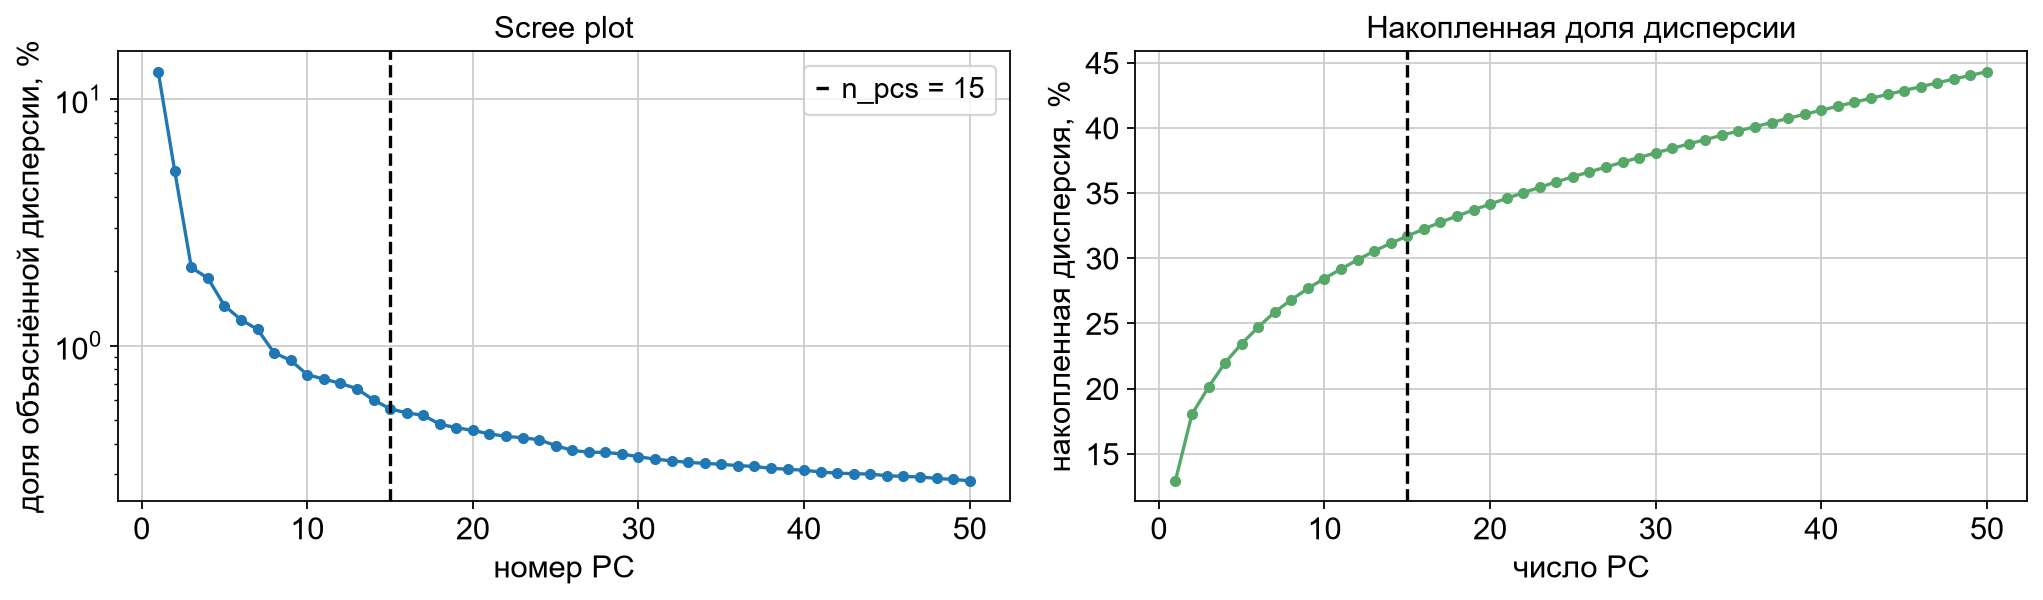

PC1     12.94
PC2      5.10
PC3      2.08
PC4      1.88
PC5      1.45
PC6      1.27
PC7      1.16
PC8      0.93
PC9      0.87
PC10     0.76
PC11     0.73
PC12     0.70
PC13     0.67
PC14     0.60
PC15     0.55
PC16     0.53
PC17     0.52
PC18     0.48
PC19     0.46
PC20     0.45

Накопленно в первых 15 PC: 31.7%


In [10]:
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=42)

vr = adata.uns["pca"]["variance_ratio"]
N_PCS = 15

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, 51), vr * 100, "o-", ms=4)
axes[0].axvline(N_PCS, ls="--", c="k", label=f"n_pcs = {N_PCS}")
axes[0].set(xlabel="номер PC", ylabel="доля объяснённой дисперсии, %",
            title="Scree plot", yscale="log")
axes[0].legend()
axes[1].plot(np.arange(1, 51), np.cumsum(vr) * 100, "o-", ms=4, c="#55A868")
axes[1].axvline(N_PCS, ls="--", c="k")
axes[1].set(xlabel="число PC", ylabel="накопленная дисперсия, %", title="Накопленная доля дисперсии")
plt.tight_layout(); plt.show()

print(pd.Series(vr[:20] * 100, index=[f"PC{i}" for i in range(1, 21)]).round(2).to_string())
print(f"\nНакопленно в первых {N_PCS} PC: {vr[:N_PCS].sum():.1%}")

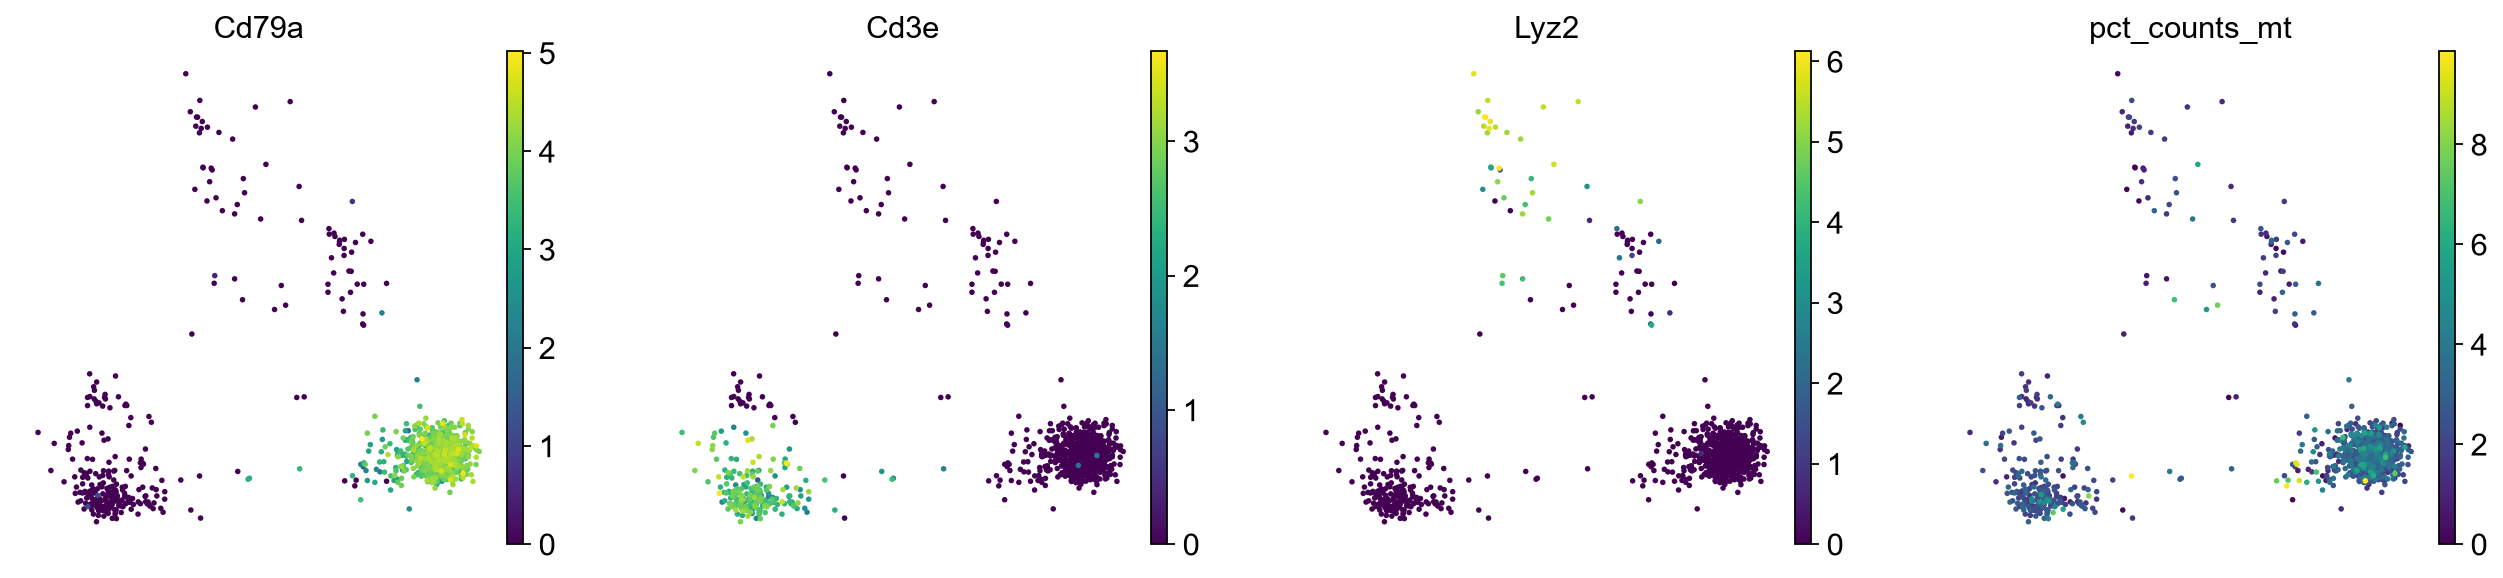

In [11]:
sc.pl.pca(adata, color=["Cd79a", "Cd3e", "Lyz2", "pct_counts_mt"], ncols=4, size=25)

**Выбор `n_pcs = 15`.** На scree plot первые компоненты резко выделяются (PC1 ≈ 13 %, PC2 ≈ 5 %, PC3–PC7 ≈ 1–2 %), затем вклад плавно падает и примерно после **PC10–15 выходит на плато** ≈ 0.4–0.6 %, где компоненты почти одинаковы и в основном описывают шум. 15 PC берём с запасом за «локтем», чтобы не потерять малые популяции (NK, DC, нейтрофилы — по несколько десятков клеток), которые могут разделяться только на поздних компонентах; при этом шумовые PC из плато не добавляем.

Накопленная доля дисперсии невелика (~30 %) — это нормально для scRNA-seq: большая часть дисперсии в разреженных счётчиках — технический шум, поэтому ориентируемся на форму кривой, а не на «80 % дисперсии».

Уже PC1/PC2 разделяют B-клетки (Cd79a), T-клетки (Cd3e) и миелоидные клетки (Lyz2), а `pct_counts_mt` не формирует отдельного направления — хорошо, после QC главные оси отражают биологию, а не качество клеток.

## 2.4. Граф соседей и Leiden

Параметры:

- **`n_neighbors = 15`** — значение по умолчанию; для ~1000 клеток это ≈ 1.5 % выборки. Меньшие значения дают более фрагментированный граф, большие — сглаживают малые популяции (самые маленькие группы здесь имеют ~15–40 клеток, их не хочется «растворить» в соседях).
- **`n_pcs = 15`** — по анализу scree plot выше.
- **`resolution = 0.5`** — выбрано после сравнения нескольких значений (таблица ниже). Набор маленький (~1000 клеток), а ожидаемые крупные популяции селезёнки — B, T, NK и миелоидные клетки, поэтому разумно умеренное разрешение. Разбиение при 0.3 и 0.5 почти совпадает (6 кластеров) — значит, оно **устойчиво** к изменению параметра. При 0.8–1.0 число кластеров скачком растёт до 11–13, причём в основном за счёт дробления крупных B- и T-популяций на подкластеры, различие которых без дифференциального анализа (который в задании не используется) не проверить. Единственное «интересное» разделение при 1.0 — миелоидный кластер 4 распадается на две группы по ~35 клеток; ниже видно, что этот кластер действительно неоднороден, и это учитываем в интерпретации, не повышая разрешение для всего набора.

In [12]:
N_NEIGHBORS = 15
RESOLUTION = 0.5

sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS, metric="euclidean",
                method="umap", random_state=42)

summary = {}
for res in [0.3, 0.5, 0.8, 1.0]:
    key = f"leiden_{res}"
    sc.tl.leiden(adata, resolution=res, key_added=key, random_state=42)
    sizes = adata.obs[key].value_counts().sort_index()
    summary[res] = {"кластеров": len(sizes), "размеры кластеров": sizes.tolist()}
pd.DataFrame(summary).T

,кластеров,размеры кластеров
0.3,6,"[458, 219, 184, 112, 69, 25]"
0.5,6,"[486, 208, 178, 101, 69, 25]"
0.8,11,"[277, 149, 116, 100, 94, 93, 89, 53, 36, 35, 25]"
1.0,13,"[184, 111, 104, 94, 94, 91, 91, 89, 62, 51, 36..."


Как кластеры при `resolution=0.5` (строки) распадаются при `resolution=1.0` (столбцы):

In [13]:
pd.crosstab(adata.obs["leiden_0.5"], adata.obs["leiden_1.0"])

leiden_1.0,0,1,2,3,4,5,6,7,8,9,10,11,12
leiden_0.5,,,,,,,,,,,,,
0,184,0,4,91,0,45,50,0,62,48,0,2,0
1,0,111,0,0,94,0,0,0,0,3,0,0,0
2,0,0,0,2,0,46,41,89,0,0,0,0,0
3,0,0,100,1,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,36,33,0
5,0,0,0,0,0,0,0,0,0,0,0,0,25


n_neighbors = 15, n_pcs = 15, resolution = 0.5
Число кластеров: 6



leiden,0,1,2,3,4,5
число клеток,486,208,178,101,69,25


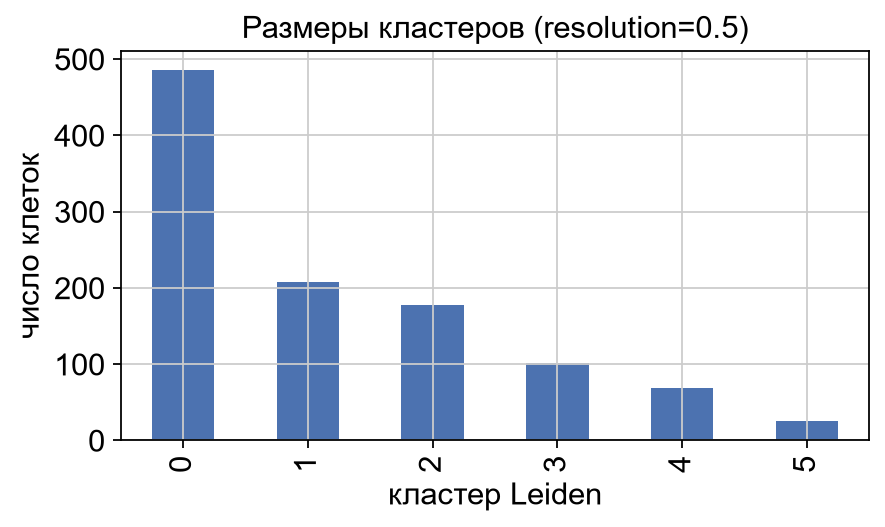

In [14]:
adata.obs["leiden"] = adata.obs[f"leiden_{RESOLUTION}"]
sizes = adata.obs["leiden"].value_counts().sort_index()

print(f"n_neighbors = {N_NEIGHBORS}, n_pcs = {N_PCS}, resolution = {RESOLUTION}")
print(f"Число кластеров: {len(sizes)}\n")
display(sizes.rename("число клеток").to_frame().T)

ax = sizes.plot.bar(figsize=(6, 3.2), color="#4C72B0")
ax.set(xlabel="кластер Leiden", ylabel="число клеток", title=f"Размеры кластеров (resolution={RESOLUTION})")
plt.show()

## 2.5. UMAP и t-SNE

Обе визуализации строятся для одних и тех же клеток и одинаково окрашены метками Leiden. UMAP использует уже построенный граф соседей, t-SNE — те же 15 PC.

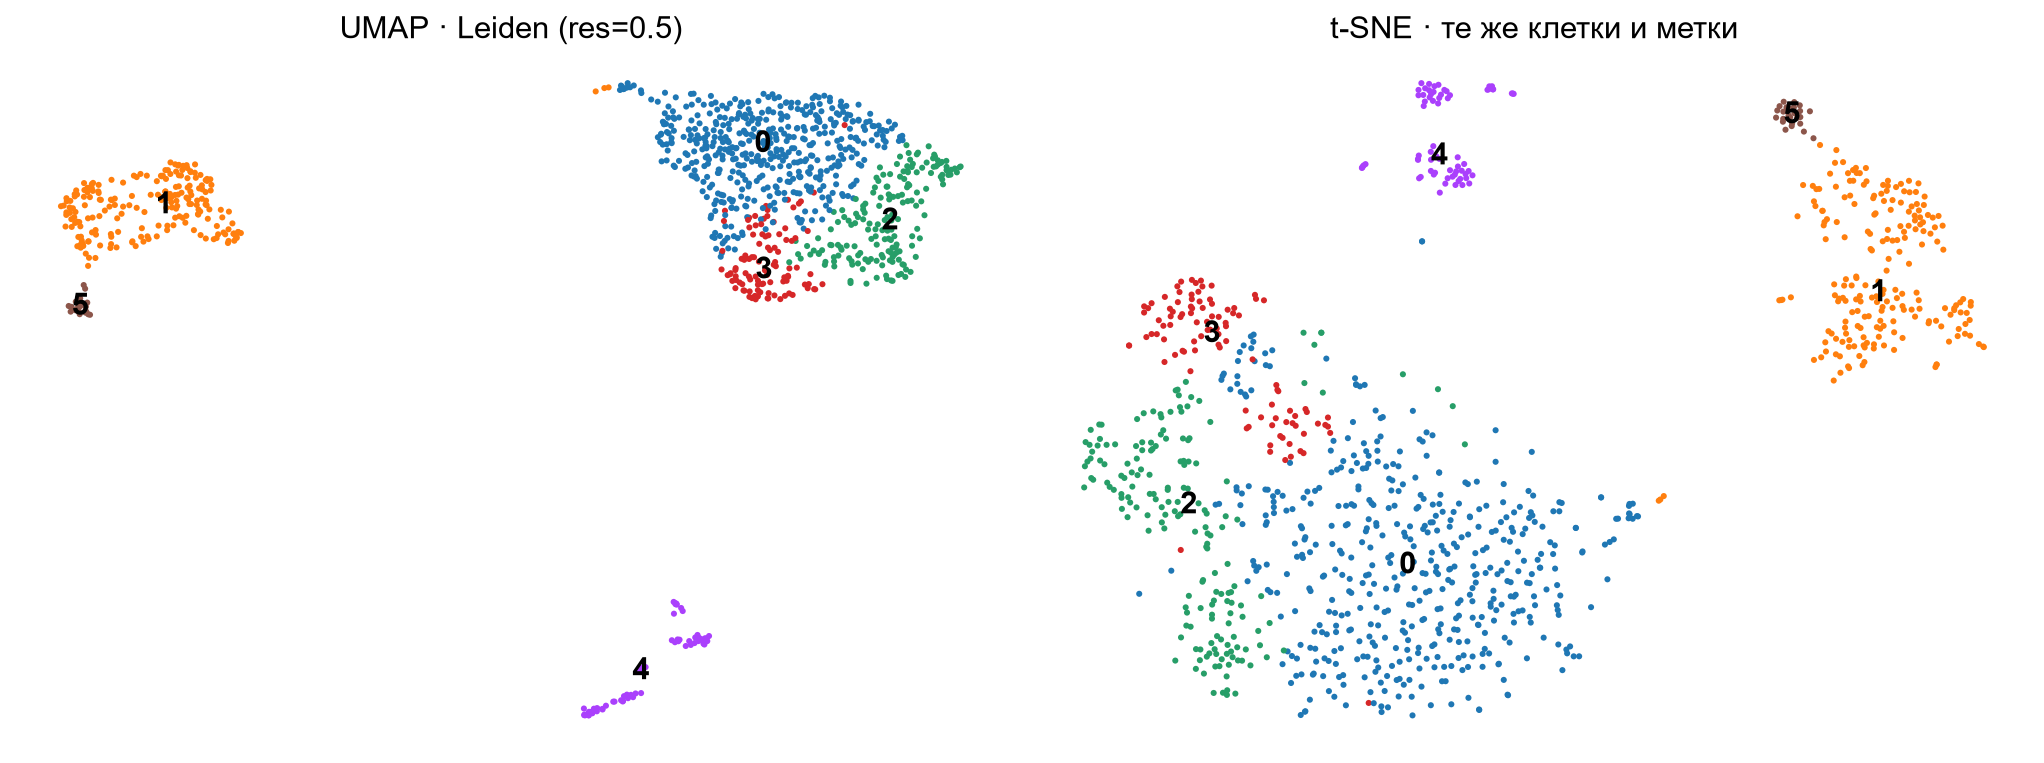

In [15]:
sc.tl.umap(adata, min_dist=0.3, random_state=42)
sc.tl.tsne(adata, use_rep="X_pca", n_pcs=N_PCS, perplexity=30, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc.pl.umap(adata, color="leiden", legend_loc="on data", title=f"UMAP · Leiden (res={RESOLUTION})",
           ax=axes[0], show=False, size=30)
sc.pl.tsne(adata, color="leiden", legend_loc="on data", title="t-SNE · те же клетки и метки",
           ax=axes[1], show=False, size=30)
plt.tight_layout(); plt.show()

**Что видно.** Обе карты согласованы с кластеризацией: кластеры 0, 2, 3 образуют одну большую область, кластеры 1 и 5 — отдельную область рядом друг с другом, кластер 4 — изолированную группу (на UMAP — из нескольких фрагментов). Границы между 0, 2 и 3 размыты на обеих картах — это скорее непрерывный «континуум» внутри одной популяции, чем резко разделённые группы.

**Чего по этим картам сказать нельзя:**

- расстояния между удалёнными островами на UMAP/t-SNE и их взаимное расположение **не интерпретируются** (например, то, что кластер 4 нарисован внизу далеко от остальных, не значит, что он «дальше всех» биологически);
- размер и плотность «облака» не отражают размер или гетерогенность популяции (t-SNE особенно выравнивает плотности);
- то, что кластер выглядит отдельным пятном, не доказывает, что это отдельный клеточный тип: кластеры получены Leiden на графе в пространстве 15 PC, а 2D-карта — только визуализация.

### QC-метрики на UMAP

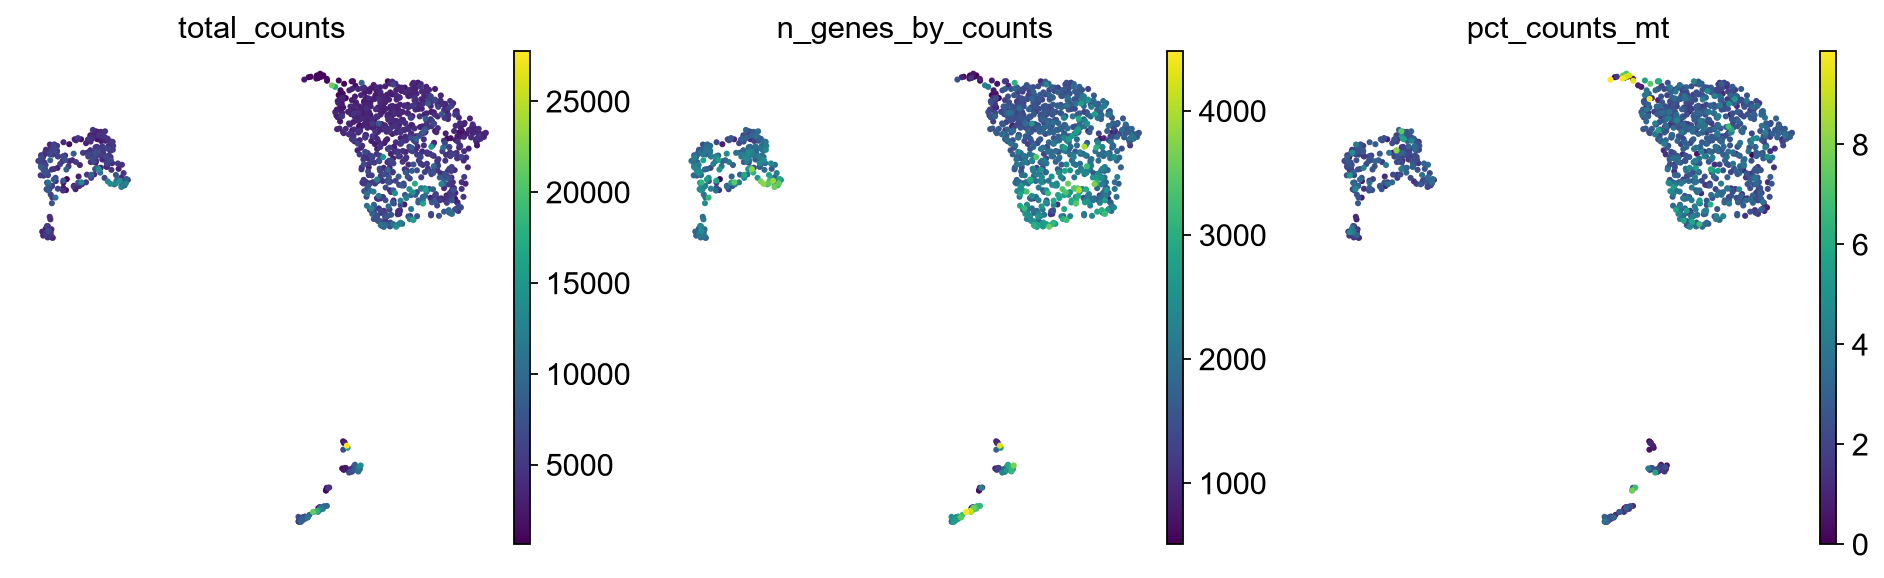

In [16]:
sc.pl.umap(adata, color=["total_counts", "n_genes_by_counts", "pct_counts_mt"], ncols=3,
           size=30, cmap="viridis")

QC-метрики распределены по карте в целом равномерно, отдельного «кластера плохих клеток» нет. Заметны две особенности:

- миелоидные клетки (кластер 4) и часть T/NK-клеток имеют больше UMI и генов, чем основная масса B-клеток. Это ожидаемо: у мелких покоящихся лимфоцитов транскриптом меньше, чем у моноцитов/DC;
- небольшой «хвостик» на краю B-области (верхний левый край кластера 0) имеет мало UMI и повышенную долю mt (~8–10 %, у границы нашего порога) — вероятно, это клетки худшего качества, а не отдельная популяция. Это аргумент, что порог 10 % не слишком мягкий для основной массы клеток, но оставшийся хвост стоит держать в уме.

### Выбранные гены

Два основных гена (по заданию), выбранных по литературе:

- **`Cd79a`** — компонент B-клеточного рецептора (Igα), классический маркер B-лимфоцитов;
- **`Cd3e`** — субъединица комплекса TCR/CD3, маркер T-лимфоцитов.

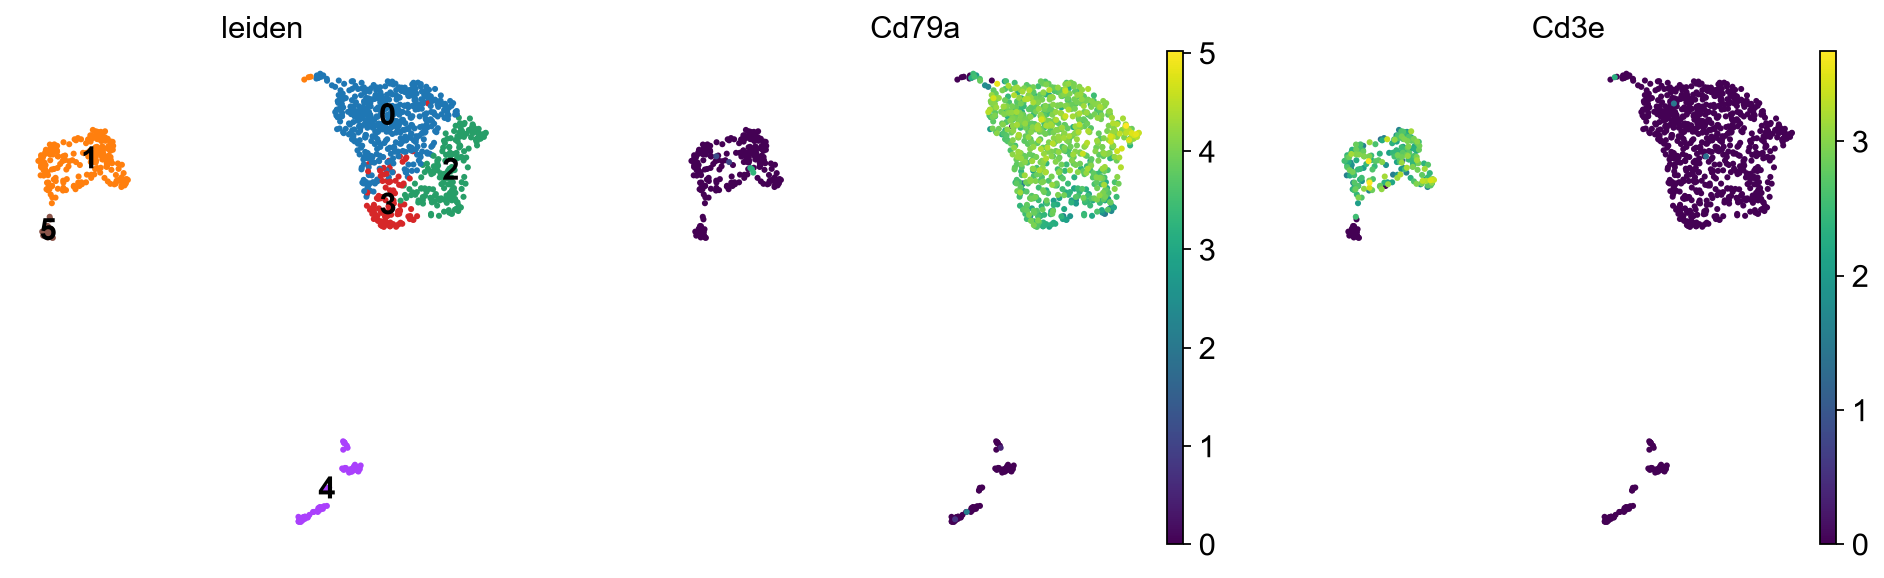

In [17]:
sc.pl.umap(adata, color=["leiden", "Cd79a", "Cd3e"], ncols=3, size=30, legend_loc="on data")

Чтобы проверить остальные (не B/T) кластеры, дополнительно смотрим заданные вручную маркеры других популяций селезёнки:

| Ген | Ожидаемая популяция |
|---|---|
| `Ms4a1` (CD20) | B-клетки |
| `Cd8a`, `Cd4` | цитотоксические / хелперные T-клетки |
| `Nkg7`, `Gzma` | NK-клетки (и цитотоксические T) |
| `Lyz2` | моноциты, макрофаги, нейтрофилы |
| `S100a8` | нейтрофилы (и часть моноцитов) |
| `C1qa` | макрофаги красной пульпы |
| `Itgax` (CD11c), `H2-Ab1` (MHC-II) | дендритные клетки (MHC-II также на B-клетках и макрофагах) |
| `Hbb-bs` | эритроидные клетки / загрязнение гемоглобиновой РНК |

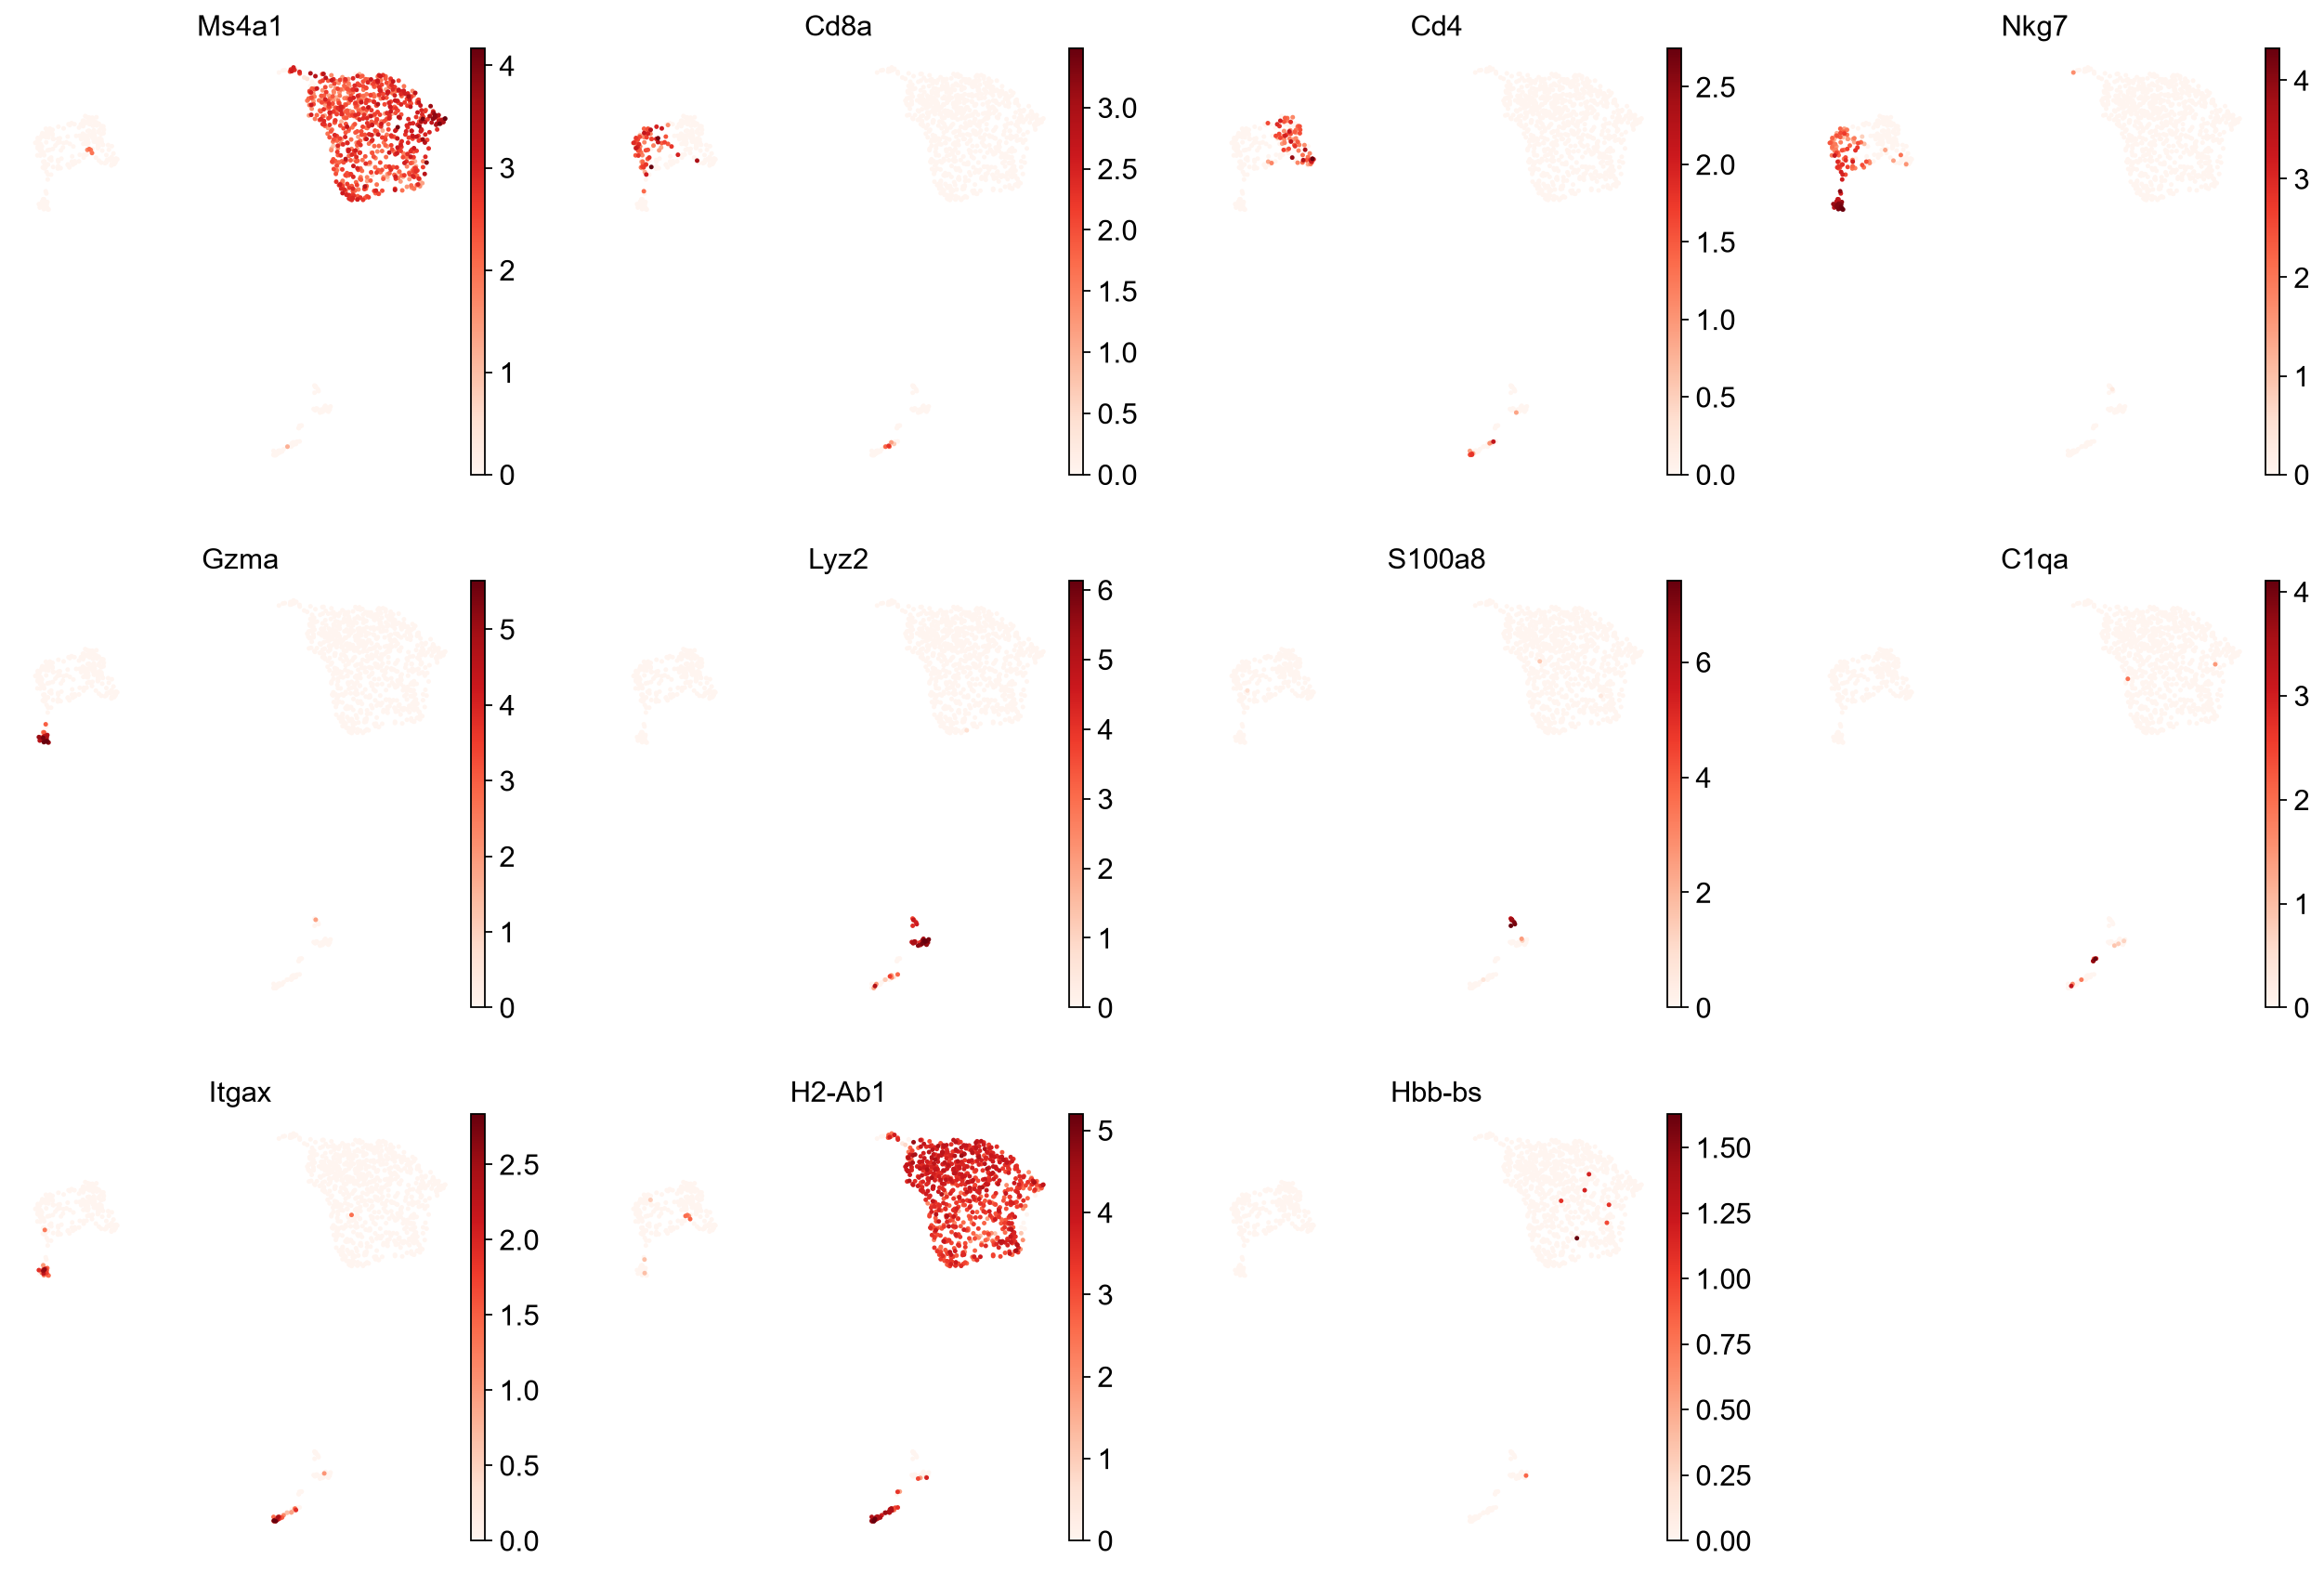

In [18]:
extra = ["Ms4a1", "Cd8a", "Cd4", "Nkg7", "Gzma", "Lyz2", "S100a8", "C1qa", "Itgax", "H2-Ab1", "Hbb-bs"]
sc.pl.umap(adata, color=extra, ncols=4, size=20, cmap="Reds")

Средняя log-нормализованная экспрессия этих генов по кластерам (простое `groupby().mean()` по заданным вручную генам, без автоматического поиска маркеров):

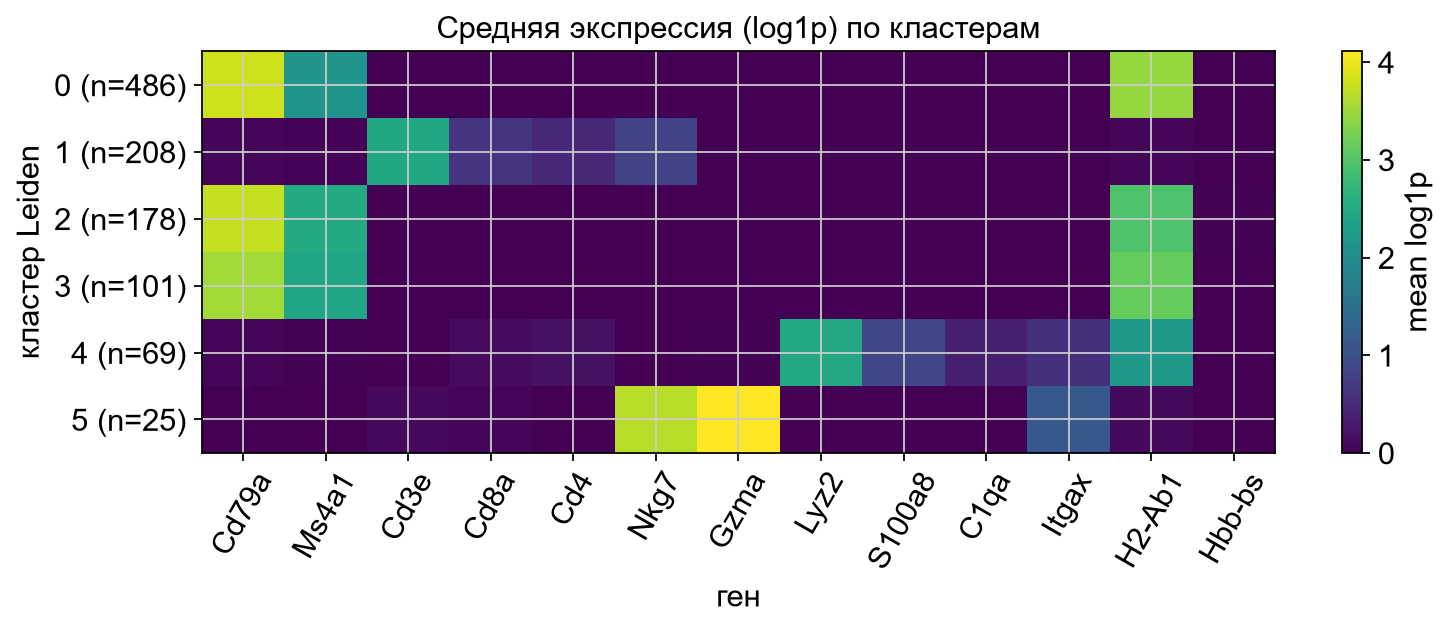

,n_cells,Cd79a,Ms4a1,Cd3e,Cd8a,Cd4,Nkg7,Gzma,Lyz2,S100a8,C1qa,Itgax,H2-Ab1,Hbb-bs
leiden,,,,,,,,,,,,,,
0,486,3.82,2.15,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.46,0.01
1,208,0.06,0.04,2.47,0.64,0.48,0.84,0.00,0.00,0.00,0.00,0.01,0.05,0.00
2,178,3.75,2.51,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.00,2.96,0.02
3,101,3.54,2.41,0.01,0.00,0.00,0.00,0.00,0.01,0.00,0.00,0.01,3.13,0.00
4,69,0.05,0.02,0.00,0.12,0.19,0.00,0.03,2.48,0.87,0.36,0.56,2.22,0.01
5,25,0.00,0.00,0.10,0.07,0.00,3.66,4.11,0.00,0.00,0.00,1.13,0.10,0.00


In [19]:
genes_panel = ["Cd79a", "Ms4a1", "Cd3e", "Cd8a", "Cd4", "Nkg7", "Gzma",
               "Lyz2", "S100a8", "C1qa", "Itgax", "H2-Ab1", "Hbb-bs"]
expr = pd.DataFrame(adata[:, genes_panel].X.toarray(), index=adata.obs_names, columns=genes_panel)
mean_expr = expr.groupby(adata.obs["leiden"], observed=True).mean()
mean_expr.insert(0, "n_cells", sizes)

fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(mean_expr[genes_panel].values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(genes_panel)), genes_panel, rotation=60)
ax.set_yticks(range(len(mean_expr)), [f"{c} (n={n})" for c, n in zip(mean_expr.index, mean_expr["n_cells"])])
ax.set(xlabel="ген", ylabel="кластер Leiden", title="Средняя экспрессия (log1p) по кластерам")
plt.colorbar(im, label="mean log1p")
plt.tight_layout(); plt.show()

mean_expr.round(2)

## 2.6. Биологический вывод

По экспрессии заданных вручную маркеров в селезёнке **предположительно** присутствуют следующие популяции (это гипотезы на основе нескольких генов, а не достоверная аннотация):

| Кластер (res=0.5) | Клеток | Что экспрессируется | Предположение |
|---|---|---|---|
| 0, 2, 3 | 486 + 178 + 101 = 765 (~72 %) | высокие `Cd79a`, `Ms4a1`, MHC-II `H2-Ab1`; нет `Cd3e` | **B-лимфоциты** |
| 1 | 208 (~19 %) | `Cd3e`; внутри — отдельные области `Cd4` и `Cd8a`, часть клеток с `Nkg7` | **T-лимфоциты** (CD4⁺ и CD8⁺) |
| 5 | 25 | `Nkg7`, `Gzma`, без `Cd3e` | **NK-клетки** |
| 4 | 69 | `Lyz2`; в одной части `S100a8`, в другой `Itgax`, `H2-Ab1`, `C1qa` | **миелоидные клетки**: вероятно смесь нейтрофилов/моноцитов и дендритных клеток/макрофагов |

**Обоснование.**

- **B-клетки** — самая многочисленная популяция, что соответствует известному составу селезёнки мыши (B-клеток там около половины и более от всех спленоцитов). `Cd79a` (Igα) и `Ms4a1` (CD20) специфичны для B-линии, высокий MHC-II (`H2-Ab1`) типичен для B-клеток как антигенпрезентирующих клеток. Разбиение B-клеток на три кластера (0/2/3) по этим генам не объясняется: оно может отражать, например, фолликулярные vs маргинальной зоны B-клетки или разное качество/размер клеток (у кластера 3 больше генов на клетку), но проверить это без дифференциального анализа нельзя — поэтому мы **не** называем подкластеры отдельными типами.
- **T-клетки** — `Cd3e` (часть комплекса CD3–TCR) экспрессируется только в кластере 1; внутри него экспрессия `Cd4` и `Cd8a` занимает разные области, что согласуется с присутствием хелперных и цитотоксических T-клеток. Leiden при `resolution=0.5` их не разделил — это вопрос масштаба, а не отсутствия различий.
- **NK-клетки** — `Nkg7` и гранзим `Gzma` (цитотоксические гранулы) при отсутствии `Cd3e`. Расположение рядом с T-клетками на карте согласуется с общими цитотоксическими программами, но, как сказано выше, близость на UMAP сама по себе не доказательство.
- **Миелоидные клетки** — `Lyz2` (лизоцим) отличает их от лимфоцитов. Внутри кластера маркеры распределены неравномерно: `S100a8` (типичен для нейтрофилов) и `Itgax`/CD11c + MHC-II (дендритные клетки) + `C1qa` (макрофаги красной пульпы) окрашивают разные фрагменты. Поэтому кластер 4 — скорее объединение нескольких редких миелоидных популяций, которые при ~70 клетках и `resolution=0.5` не выделились отдельно (при `resolution=1.0` он распадается на две части).
- **Эритроидные клетки** отдельной группы не образуют: `Hbb-bs` встречается лишь в единичных клетках, вероятно как фоновая (ambient) РНК. Это ожидаемо, так как при подготовке спленоцитов эритроциты обычно лизируют.

**Ограничения.** Выводы основаны на ~13 генах и одном образце ~1000 клеток; редкие популяции (pDC, плазматические клетки, γδ T и др.) при таком размере выборки могли не выделиться или попасть в более крупные кластеры. Для уверенной аннотации нужны дифференциальная экспрессия, больше маркеров и/или референсные данные — что выходит за рамки этого задания.